# Sampling a year of North Atlantic weather with a pure LIM

How much does a 15-day mean wind change if August has the same sea and atmosphere, but the daily weather plays out differently? This tutorial starts with that experiment. We will also generate a leap year and measure how much wind variance survives averaging over 1, 5, 10, 15 and 31 days.

A **linear inverse model** (LIM) learns how anomalies on earlier days relate to anomalies on the next day. Gaussian random draws supply the unpredictable part. The full release contains one fitted model per calendar month. All examples below run offline on a CPU from those weights. The raw-data and full-refit commands appear at the end. Dependencies and launch instructions are in the [README](../README.md).

In [1]:
from pathlib import Path
import calendar
import os
import sys
import tempfile

import numpy as np
import pandas as pd
import xarray as xr
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display

search_from = Path(os.environ.get("ANNUAL_LIM_ROOT", ".")).resolve()
root = next(p for p in (search_from, *search_from.parents) if (p / "src/annual_lim").is_dir())
sys.path.insert(0, str(root / "src"))
from annual_lim.forcing import rebuild
from annual_lim.layout import design
from annual_lim.model import MonthlyModel
from annual_lim.sample import event, write, year_sample
from annual_lim.statistics import metrics, trace_lags
from tc_emulator.diagnostics import region_area
from tc_emulator.wind_lim import fit_dynamics

config = root / "configs/annual_lim"
candidates = [Path(os.environ["ANNUAL_LIM_WEIGHTS"])] if "ANNUAL_LIM_WEIGHTS" in os.environ else []
candidates += [root / "weights", root / "runs/annual_lim/weights", root / "work/weights"]
weights = next((p for p in candidates if all((p / f"{m:02}/model.json").is_file() for m in range(1, 13))), None)
if weights is None:
    raise FileNotFoundError("Open the full release, or set ANNUAL_LIM_WEIGHTS to your fitted weights directory.")
workspace = tempfile.TemporaryDirectory()
work = Path(workspace.name)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## 1. Put the warming input and calendar on the same footing

The scalar $g$ is an annual global temperature anomaly, in K relative to 1850–1900. If $T_{im}$ is the global mean temperature for fitting member $i$ in month $m$ of a chosen year, and $d_m$ is the number of days in that month, its annual temperature is $\sum_m d_m T_{im}/\sum_m d_m$. Average those annual values across the 35 fitting members, then subtract their 1850–1900 baseline. For a temperature *difference*, 1 K and 1 °C have the same numerical size.

A member is a simulation with its own realization of weather. Member identities and selected years are separated across the three roles. Each calendar month receives one observation per member-year. A leap-year February supplies 29 daily winds and one monthly background.

In [2]:
settings, cases = design(config)
cases = pd.DataFrame(cases, columns=["role", "member", "year", "g_K"])
summary = cases.groupby("role", sort=False).agg(members=("member", "nunique"), years=("year", "nunique"),
                                                  records_per_month=("year", "size"))
summary["member_months"] = 12 * summary.records_per_month
baseline = rebuild(config, work / "warming.csv")
annual_g = pd.read_csv(work / "warming.csv").set_index("year").g
reference_g = pd.read_csv(config / "forcing.csv").set_index("year").g
np.testing.assert_allclose(annual_g, reference_g, atol=2e-12, rtol=0)
display(summary)
print(f"Baseline = {baseline:.4f} °C. February has {calendar.monthrange(2048, 2)[1]} days in 2048.")

,members,years,records_per_month,member_months
role,,,,
train,35,15,525,6300
val,7,6,42,504
test,8,15,120,1440


Baseline = 13.5074 °C. February has 29 days in 2048.


### Prepare one ocean column

Mixed-layer depth is the depth of the well-mixed upper ocean. The preprocessing code estimates the temperature slope over the next 100 m using the native depth levels and interpolated endpoints. Try a synthetic column whose temperature decreases by 0.03 K for each metre of depth. The same function that prepares MPI columns should return a cooling gradient of 3 K per 100 m. A second shallow column ends before the requested lower endpoint and retains a missing value.

In [3]:
from tc_emulator.physical import gradient

depth_m = np.array([5., 25., 55., 90., 130., 170.])
one_column = 300. - .03 * depth_m
profiles = np.broadcast_to(one_column[:, None, None], (6, 1, 2)).copy()
profiles[4:, 0, 1] = np.nan
mld_m = np.array([[20., 20.]])
cooling, report = gradient(depth_m, profiles, mld_m, height=100.)
np.testing.assert_allclose(cooling[0, 0], 3., atol=1e-10)
assert np.isnan(cooling[0, 1])
display(pd.DataFrame({"mixed-layer depth (m)": mld_m.ravel(), "cooling gradient (K/100 m)": cooling.ravel()},
                     index=["deep column", "shallow column"]))

,mixed-layer depth (m),cooling gradient (K/100 m)
deep column,20.0,3.0
shallow column,20.0,NaN


## 2. From a physical map to a few coordinates

A gridded field becomes a column vector $f$. Its training mean is $\bar f$. A diagonal matrix $D$ weights the cells and scales each channel. The columns of $U$ are orthonormal spatial patterns (empirical orthogonal functions, or EOFs). The coordinates of an anomaly are $z=U^\mathsf{T}D(f-\bar f)$. Multiplying by $D^{-1}U$ and adding $\bar f$ reconstructs a map on the valid cells. Keeping fewer columns smooths away some fine structure.

Here two equally weighted cells have a common pattern and a contrast pattern. A +2 K anomaly in the first cell projects onto both. Drop the contrast coordinate and see what each cell retains.

In [4]:
mean_map = np.array([25., 26.])
field = mean_map + [2., 0.]
D = np.diag(np.sqrt([0.5, 0.5]))
U = np.array([[1., 1.], [1., -1.]]) / np.sqrt(2)
coordinates = U.T @ D @ (field - mean_map)
reconstructed = mean_map + np.linalg.solve(D, U @ coordinates)
common_only = mean_map + np.linalg.solve(D, U[:, :1] @ coordinates[:1])
np.testing.assert_allclose(reconstructed, field)
display(pd.DataFrame({"input (°C)": field, "both EOFs (°C)": reconstructed,
                      "common EOF only (°C)": common_only}, index=["cell 1", "cell 2"]))
print("Two coordinates:", coordinates.round(3))

,input (°C),both EOFs (°C),common EOF only (°C)
cell 1,27.0,27.0,26.0
cell 2,26.0,26.0,27.0


Two coordinates: [1. 1.]


## 3. How a warmer background reaches the wind

At fixed $g$, generate the monthly background coordinates as $z=m(g)+F(g)e$. Here $m(g)$ is the fitted background mean, $e$ has independent standard normal entries, and $F(g)F(g)^\mathsf{T}$ is the covariance matrix. The month-conditioned mean wind is $a(g)+K^\mathsf{T}[z-m(g)]$, with wind intercept $a(g)$ and fitted transfer matrix $K$. A wind direction described by a column $k$ therefore receives background variance $k^\mathsf{T}F F^\mathsf{T}k$.

Try a two-coordinate example with $k=(0.6,0.8)^\mathsf{T}$. The second background coordinate shares part of the first coordinate's random draw. This makes their covariance positive. The last line applies exactly the same computation to the real fitted August background, summed over both steering components and over the basin. Steering wind here gives weight 0.2 to the 250 hPa wind and 0.8 to the 850 hPa wind.

In [5]:
F = np.array([[2., 0.], [0.5, 1.]])
k = np.array([0.6, 0.8])
covariance = F @ F.T
e = np.random.default_rng(42).normal(size=(50_000, 2))
observed_variance = (e @ F.T @ k).var()
print("Background covariance matrix:\n", covariance)
print(f"Toy wind variance: exact {k @ covariance @ k:.3f}, sampled {observed_variance:.3f}")

from tc_emulator.warming_circulation import transfer_matrix
august = MonthlyModel(weights, 8)
area, ocean, all_metrics = metrics(august.rep)
G = all_metrics[0]  # ||v||² over both steering components and the area equals pc.T @ G @ pc.
K = transfer_matrix(august.mean)
wind_metric = K @ G @ K.T
levels = [0., 2., 4.]
background_power = [np.sum((august.factor(g) @ august.factor(g).T) * wind_metric) for g in levels]
display(pd.DataFrame({"annual warming (K)": levels, "August background contribution (m²/s²)": background_power}).round(3))

Background covariance matrix:
 [[4.   1.  ]
 [1.   1.25]]
Toy wind variance: exact 3.200, sampled 3.207


,annual warming (K),August background contribution (m²/s²)
0,0.0,1.685
1,2.0,1.408
2,4.0,1.185


## 4. Fit the daily dynamics in a small example

Let $x_t$ be the wind after subtracting its conditional monthly mean. In a two-lag model, $x_t=A_1 x_{t-1}+A_2 x_{t-2}+\epsilon_t$. The coefficients $A_1,A_2$ are learned by regressing today's anomaly on the last two days. $\epsilon_t$ is a zero-mean innovation. Stacking today's and yesterday's values forms a state with transition matrix $A$. The spectral radius $\rho(A)$ is the largest absolute eigenvalue. Values below one make errors in the initial state decay in this model.

First fit a synthetic one-component series whose two coefficients we know. Each row represents an independent month. The calculation pairs days only within a row. Then inspect the fitted January and August matrices in the real model. The real model also multiplies $A$ by a fitted retention $r$ and subtracts a fraction $b$ of the preceding 5–20-day average from the output. These adjustments control the variance of multi-day winds.

In [6]:
rng = np.random.default_rng(452)
toy = np.zeros((500, 65, 1))
for day in range(2, toy.shape[1]):
    toy[:, day, 0] = 0.65*toy[:, day-1, 0] - 0.18*toy[:, day-2, 0] + rng.normal(size=len(toy))
fit = fit_dynamics(toy[:, -31:], ridge=0., order=2)
display(pd.DataFrame([(.65, fit.a[0, 0]), (-.18, fit.a[0, 1])],
                     index=["yesterday", "two days ago"], columns=["known coefficient", "fitted coefficient"]).round(3))
monthly_models = [MonthlyModel(weights, 1), august]
display(pd.DataFrame([{"month": calendar.month_name[m.meta["month"]], "background coordinates": m.bg.beta.shape[1],
                       "wind coordinates": m.base.observed_dim, "state size": len(m.base.a), "spectral radius": m.base.rho,
                       "retention r": m.cal.retention, "feedback b": m.cal.feedback} for m in monthly_models]).round(4))

,known coefficient,fitted coefficient
yesterday,0.65,0.646
two days ago,-0.18,-0.179


,month,background coordinates,wind coordinates,state size,spectral radius,retention r,feedback b
0,January,78,120,240,0.8482,0.8450,1.0407
1,August,78,120,240,0.9471,0.8406,0.7853


## 5. Draw two August weather histories over exactly the same ocean

Set $g=2$ K and fix the year, seed and background ID. Changing only the weather ID preserves the monthly fields and draws an independent daily innovation sequence. A 15-day event stores padded time nodes for the track integrator. Day 1 at noon has coordinate 0 seconds. We plot the 15 actual days using indices 1 through 15.

In [7]:
g, seed, year, month, length = 2., 9152026, 2050, 8, 15
def draw(weather_id, days=length):
    return event(weights, month, year, g, days, seed, "fixed-ocean", weather_id)

first, second = draw("weather-A"), draw("weather-B")
for name in ("background_pc", "sst", "mld", "ta", "hus", "vpot", "conditional_wind_pc"):
    np.testing.assert_array_equal(first[name], second[name])
assert not np.array_equal(first.wind, second.wind)
longer = draw("weather-A", days=20)
np.testing.assert_allclose(first.wind, longer.wind.isel(t_seconds=slice(0, len(first.t_seconds))), atol=1e-6)
write(first, work / "august_event.nc")
with xr.open_dataset(work / "august_event.nc", decode_timedelta=False) as saved:
    assert saved.sizes["t_seconds"] == length + 3
    print(f"Saved {len(saved.t_seconds)} time nodes, {len(saved.component)} wind components, "
          f"{len(saved.lat)} latitudes and {len(saved.lon)} longitudes.")
    print("Wind channels:", ", ".join(saved.component.values))

Saved 18 time nodes, 4 wind components, 36 latitudes and 58 longitudes.
Wind channels: u250, v250, u850, v850


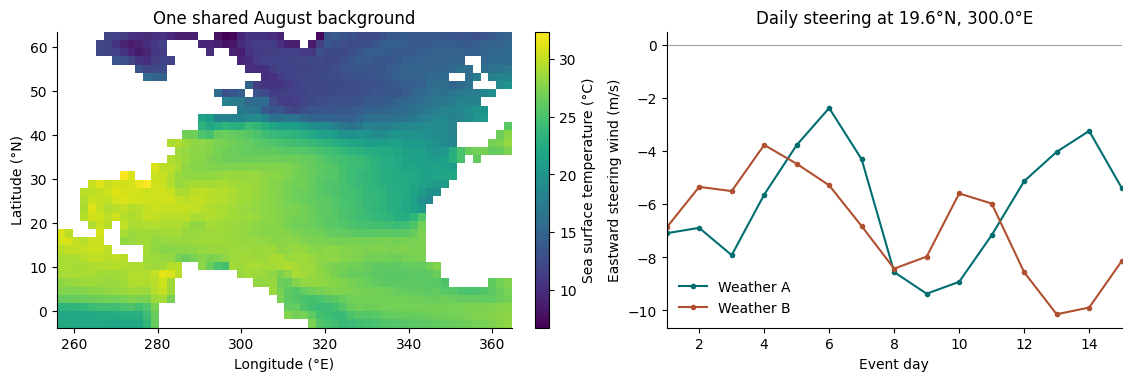

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.7), layout="constrained")
sst_c = first.sst - 273.15
sst_c.plot(ax=axes[0], cmap="viridis", cbar_kwargs={"label": "Sea surface temperature (°C)"})
axes[0].set(title="One shared August background", xlabel="Longitude (°E)", ylabel="Latitude (°N)")
point = first.sel(lat=20., lon=300., method="nearest")
for event_data, label, color in [(first, "Weather A", "#006d70"), (second, "Weather B", "#af5031")]:
    sample = event_data.wind.sel(lat=point.lat, lon=point.lon).isel(t_seconds=slice(1, length+1))
    zonal = .2*sample.sel(component="u250") + .8*sample.sel(component="u850")
    axes[1].plot(np.arange(1, length+1), zonal, marker=".", color=color, label=label)
axes[1].axhline(0, color="0.6", lw=.7)
axes[1].set(title=f"Daily steering at {float(point.lat):.1f}°N, {float(point.lon):.1f}°E",
            xlabel="Event day", ylabel="Eastward steering wind (m/s)", xlim=(1, length))
axes[1].legend(frameon=False)
plt.show()

## 6. Measure the effect of averaging for several days

Keep the background fixed. Subtracting its conditional wind leaves a zero-mean daily residual. Let $C_h$ be the area-integrated steering covariance of two residuals $h$ days apart, averaged across the eastward and northward components. For a window of $d$ days the exact variance is

$$V_d=\frac{d C_0+2\sum_{h=1}^{d-1}(d-h)C_h}{d^2}.$$

There are $d-h$ pairs at separation $h$ in one window. The model computes $C_h$ from the transition, stationary covariance and 5–20-day filter. We estimate the same quantity by drawing 384 independent August weather paths. In EOF coordinates $v$, the quadratic form $v^\mathsf{T}Gv$ is the area-weighted squared steering anomaly. We average over all possible starts inside each path. Overlapping windows share days, so the uncertainty below comes from *independent paths*. The held-out climate comparison later also varies the background.

,exact (m²/s²),sampled (m²/s²),Monte Carlo SE (m²/s²)
days,,,
1,13.613,13.609,0.063
5,6.292,6.293,0.051
10,3.398,3.404,0.038
15,2.068,2.070,0.026
31,0.558,0.561,0.010


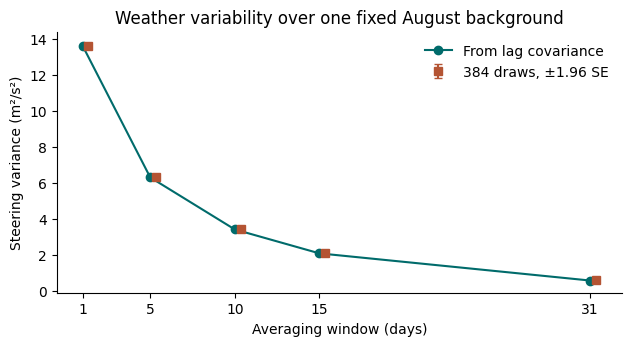

In [9]:
windows = [1, 5, 10, 15, 31]
raw_lags = trace_lags(august.base, G[None], 31 + august.cal.last_lag)[0]
exact = august.cal.window_variance(g, raw_lags, windows)[0]
path_powers = []
rng = np.random.default_rng(2026)
for batch in range(12):
    residual = august.weather.sample(np.full(32, g), 31, rng)
    cumulative = np.pad(residual.cumsum(axis=1), ((0, 0), (1, 0), (0, 0)))
    powers = []
    for d in windows:
        mean = (cumulative[:, d:] - cumulative[:, :-d]) / d
        powers.append(np.einsum("ntk,ntk->nt", mean @ G, mean).mean(axis=1))
    path_powers.append(np.stack(powers, axis=1))
power = np.concatenate(path_powers)
estimate = power.mean(axis=0)
se = power.std(axis=0, ddof=1) / np.sqrt(len(power))
comparison = pd.DataFrame({"days": windows, "exact (m²/s²)": exact, "sampled (m²/s²)": estimate,
                           "Monte Carlo SE (m²/s²)": se}).set_index("days")
display(comparison.round(3))
fig, ax = plt.subplots(figsize=(6.2, 3.35), layout="constrained")
ax.plot(windows, exact, "o-", color="#006b6b", label="From lag covariance")
ax.errorbar(np.array(windows)+.35, estimate, yerr=1.96*se, fmt="s", color="#b45433",
            capsize=3, label="384 draws, ±1.96 SE")
ax.set(xlabel="Averaging window (days)", ylabel="Steering variance (m²/s²)",
       title="Weather variability over one fixed August background", xticks=windows)
ax.legend(frameon=False)
plt.show()

## 7. Sample a leap year

Pass one annual warming level to the twelve monthly models. Each supplies its own monthly background and daily wind sequence. The annual product discards interpolation padding, attaches actual dates at noon and keeps one background for each calendar month. The monthly initial states are independently drawn. Use month-contained windows when estimating persistence from this product. A single simulated year can illustrate the seasonal cycle. Its twelve temperatures also include the random backgrounds in this particular draw.

2048-01-01 12:00:00 through 2048-12-31 12:00:00; 366 daily winds.
February contributes 29 days.


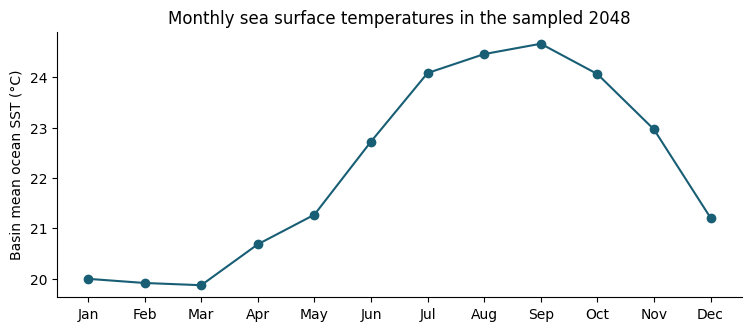

In [10]:
annual = year_sample(weights, 2048, g, seed, "example-year", "weather-A")
write(annual, work / "leap_year.nc")
with xr.open_dataset(work / "leap_year.nc") as decoded:
    dates = pd.DatetimeIndex(decoded.time.values)
    assert len(dates) == 366 and len(decoded.calendar_month) == 12
    assert dates[59] == pd.Timestamp("2048-02-29 12:00") and (np.diff(dates) == pd.Timedelta(days=1)).all()
    A = xr.DataArray(region_area(decoded.lat.values, decoded.lon.values), dims=["lat", "lon"])
    monthly_sst = (decoded.sst - 273.15).weighted(A).mean(("lat", "lon")).load()
    print(f"{dates[0]} through {dates[-1]}; {len(dates)} daily winds.")
    print("February contributes", int((dates.month == 2).sum()), "days.")
fig, ax = plt.subplots(figsize=(7.4, 3.2), layout="constrained")
ax.plot(np.arange(1, 13), monthly_sst, "o-", color="#185e75")
ax.set(xticks=np.arange(1, 13), xticklabels=list(calendar.month_abbr)[1:],
       ylabel="Basin mean ocean SST (°C)", title="Monthly sea surface temperatures in the sampled 2048")
plt.show()

## 8. Read the independent climate test

The table uses eight MPI members held out from all fitting. Five cold years, five years inside the fitted warming range and five warm years contribute 120 observations per calendar month overall. Each ratio is the model's 15-day steering variance divided by the observed MPI variance in the same group. A ratio of 1.10 means 10% too much variance. The last column applies the two training-defined checks to the pooled 15-day estimate. The full score file also contains uncertainty intervals and a paired comparison with the TC Fourier sampler.

In [11]:
scores = pd.read_csv(root / "reports/annual_lim_scores.csv", dtype={"window": str})
test = scores.query("role == 'test' and model == 'pure_lim' and window == '15'")
table = test.pivot(index="month", columns="group", values="ratio")[["cold", "inside", "warm", "all"]]
pooled = test.query("group == 'all'").set_index("month")
# The CSV also has blank flags for the 1-day and full-month descriptive rows.
yes = lambda series: series.astype(str).str.lower().eq("true")
table["pooled 15-day pass"] = yes(pooled.in_band) & yes(pooled.closer_than_iid)
table.index = [calendar.month_abbr[m] for m in table.index]
display(table.round(3))

group,cold,inside,warm,all,pooled 15-day pass
Jan,0.978,1.097,1.191,1.073,True
Feb,0.962,0.903,1.030,0.954,True
Mar,0.991,1.039,1.037,1.024,True
Apr,1.034,0.989,1.067,1.014,True
May,0.949,1.012,1.022,0.978,True
Jun,0.968,0.918,1.034,0.949,True
Jul,1.000,1.029,1.005,1.003,True
Aug,0.930,0.990,1.035,0.980,True
Sep,0.985,1.024,1.042,1.016,True
Oct,1.011,0.952,1.052,0.999,True


## 9. Reproduce the full pipeline

The commands below are for the extracted release, from the folder containing `run.py`. They are shown explicitly so that running the tutorial leaves the raw archive and fitted weights alone. `prepare` reads the nine CMIP variables listed in the catalogue. It aligns physical grids, pressure levels and CF dates, then writes twelve month files and a per-year source manifest. The first example selects one registered leap year. Omit the member filter to prepare the full design. Each monthly `train` command learns the spatial bases, warming response, two-lag transition, noise covariance and weather calibration from its 525 fitting member-months. `validate` opens the separate validation or test population. The source for each stage is under `src/annual_lim/`.

```bash
python run.py --work work prepare --member r1i1p1f1 --year 2000
python run.py --work work prepare --workers 2
python run.py --work work train --month 8
python run.py --work work validate --month 8 --role test
python run.py sample --weights work/weights --year 2050 --month 8 --g 2 --days 15 --output august.nc
```

Omit `--month` on the training and validation commands to fit or assess every month. For the full derivation and the exact August variance calculation, read the [English linear algebra notes](../reports/annual_lim_linear_algebra.md). The [Chinese guide](../reports/annual_lim_guide.md) covers the workflow, and the [results](../reports/annual_lim_results.md) give the physical wind checks and temperature-specific comparisons.

**Try two variations.** Change the annual warming in the background-variance cell and trace what changes through $F(g)$. Then change only the weather ID in the event cell and verify that sea surface temperature stays fixed while the 15-day mean wind changes.